In [1]:
print("Customer Segmentation & Retention")


Customer Segmentation & Retention


In [9]:
# 1. Import Libraries
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_excel(r"C:\Users\USER\Desktop\Customer Segmentation and Retention\raw_data.xlsx")
df.head()


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [10]:
# 2. Data Cleaning
df.drop_duplicates(inplace=True)
df.dropna(subset=["CustomerID"], inplace=True)
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

df = df[
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0) &
    (~df["InvoiceNo"].astype(str).str.startswith("C"))
].copy()

df["Revenue"] = df["Quantity"] * df["UnitPrice"]
print(df.shape)

(392692, 9)


In [11]:
df.isnull().sum()

InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
Revenue        0
dtype: int64

In [12]:
# 3. Customer Analysis
customers = df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", "max"),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum")
).reset_index()

analysis_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)
customers["Recency"] = (
    analysis_date - customers["Recency"]
).dt.days

customers.head()

,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,1,77183.60
1,12347.0,2,7,4310.00
2,12348.0,75,4,1797.24
3,12349.0,19,1,1757.55
4,12350.0,310,1,334.40


In [13]:
# 4. RFM Scoring
customers["R_Score"] = pd.qcut(
    customers["Recency"].rank(method="first"),
    5, labels=[5, 4, 3, 2, 1]
).astype(int)

customers["F_Score"] = pd.qcut(
    customers["Frequency"].rank(method="first"),
    5, labels=[1, 2, 3, 4, 5]
).astype(int)

customers["M_Score"] = pd.qcut(
    customers["Monetary"].rank(method="first"),
    5, labels=[1, 2, 3, 4, 5]
).astype(int)

customers["RFM_Score"] = (
    customers["R_Score"].astype(str) +
    customers["F_Score"].astype(str) +
    customers["M_Score"].astype(str)
)

customers.head()

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
0,12346.0,326,1,77183.60,1,1,5,115
1,12347.0,2,7,4310.00,5,5,5,555
2,12348.0,75,4,1797.24,2,4,4,244
3,12349.0,19,1,1757.55,4,1,4,414
4,12350.0,310,1,334.40,1,1,2,112


In [14]:
# 5. Customer Segmentation
def segment(row):
    if row["R_Score"] >= 4 and row["F_Score"] >= 4:
        return "Champions"
    elif row["F_Score"] >= 4:
        return "Loyal Customers"
    elif row["R_Score"] <= 2:
        return "At Risk"
    else:
        return "Regular Customers"

customers["Segment"] = customers.apply(segment, axis=1)
customers.head()

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment
0,12346.0,326,1,77183.60,1,1,5,115,At Risk
1,12347.0,2,7,4310.00,5,5,5,555,Champions
2,12348.0,75,4,1797.24,2,4,4,244,Loyal Customers
3,12349.0,19,1,1757.55,4,1,4,414,Regular Customers
4,12350.0,310,1,334.40,1,1,2,112,At Risk


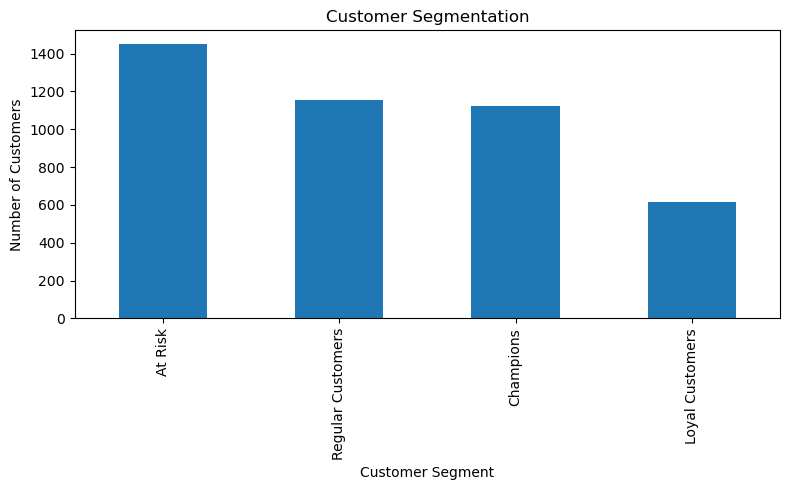

In [15]:
# 6. Segment Visualization
customers["Segment"].value_counts().plot(
    kind="bar", figsize=(8, 5)
)

plt.title("Customer Segmentation")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

In [16]:
# 7. Export Customer Data
customers.to_csv("customer_segments.csv", index=False)

print("Python analysis completed successfully!")

Python analysis completed successfully!
